# Data Understanding on the Brazillian E-Commerce Dataset

Deskripsi:

Data ini berisi data E-commerce Brazil disediakan Olist, sebuah perusahaan startup asal negara tersebut. Berdasarkan informasi yang diberikan, dataset berisi **100k** jumlah orders dari tahun 2016-2018 yang dibuat di berbagai e-commerce Brazil. Data yang dimuat mencakup:

- status, 
- price, 
- payment and 
- freight performance to customer location, 
- product attributes and 
- finally reviews by customers

*Perhatian
Satu pesanan mungkin terdiri dari beberapa item.
Setiap item mungkin dipenuhi oleh penjual yang berbeda.
Semua teks yang mengidentifikasi toko dan mitra telah diganti dengan nama-nama keluarga besar (Great Houses) dari *Game of Thrones*.*

Notebook ini bertujuan untuk memahami data, mengetahui alasan dibalik beberapa file/tabel, mengetahui arti setiap kolom, relasi antar tabel, distribusi data, serta kualitas data. Diharapan proses ini berjalan dalam waktu **7 hari** kedepan


## 1. Load Data

In [56]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt 

In [6]:
data_dir = Path('dataset')

In [7]:
data_dir.exists()

True

In [8]:
files = list(data_dir.glob('*.csv'))
files

[PosixPath('dataset/olist_sellers_dataset.csv'),
 PosixPath('dataset/product_category_name_translation.csv'),
 PosixPath('dataset/olist_orders_dataset.csv'),
 PosixPath('dataset/olist_order_items_dataset.csv'),
 PosixPath('dataset/olist_customers_dataset.csv'),
 PosixPath('dataset/olist_geolocation_dataset.csv'),
 PosixPath('dataset/olist_order_payments_dataset.csv'),
 PosixPath('dataset/olist_order_reviews_dataset.csv'),
 PosixPath('dataset/olist_products_dataset.csv')]

In [10]:
for file in files:
    print(file.name)

olist_sellers_dataset.csv
product_category_name_translation.csv
olist_orders_dataset.csv
olist_order_items_dataset.csv
olist_customers_dataset.csv
olist_geolocation_dataset.csv
olist_order_payments_dataset.csv
olist_order_reviews_dataset.csv
olist_products_dataset.csv


In [120]:
sellers = pd.read_csv(data_dir / "olist_sellers_dataset.csv")
customers = pd.read_csv(data_dir / "olist_customers_dataset.csv")
products = pd.read_csv(data_dir / "olist_products_dataset.csv")
geolocation = pd.read_csv(data_dir / "olist_geolocation_dataset.csv")
orders = pd.read_csv(data_dir / "olist_orders_dataset.csv")
order_item = pd.read_csv(data_dir / "olist_order_items_dataset.csv")
payments = pd.read_csv(data_dir / "olist_order_payments_dataset.csv")
reviews = pd.read_csv(data_dir / "olist_order_reviews_dataset.csv")
translated_products = pd.read_csv(data_dir / "product_category_name_translation.csv")


Available Datasets

The project contains several datasets related to sellers, translated product category, orders, items, customers, geolocation, payments, reviews, and product.

### SELLERS

In [14]:
sellers.head()

,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


In [ ]:
m_s = sellers.shape[0]
n_s = sellers.shape[1]

print(f"Number of rows: {m_s}")
print(f"Number of column: {n_s}")

Number of rows: 3095
Number of column: 4


In [17]:
sellers.columns

Index(['seller_id', 'seller_zip_code_prefix', 'seller_city', 'seller_state'], dtype='str')

In [15]:
sellers.info()

<class 'pandas.DataFrame'>
RangeIndex: 3095 entries, 0 to 3094
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   seller_id               3095 non-null   str  
 1   seller_zip_code_prefix  3095 non-null   int64
 2   seller_city             3095 non-null   str  
 3   seller_state            3095 non-null   str  
dtypes: int64(1), str(3)
memory usage: 96.8 KB


In [18]:
sellers.isna().sum()

seller_id                 0
seller_zip_code_prefix    0
seller_city               0
seller_state              0
dtype: int64

In [19]:
sellers.nunique()

seller_id                 3095
seller_zip_code_prefix    2246
seller_city                611
seller_state                23
dtype: int64

In [126]:
sellers["seller_id"].duplicated().sum()

np.int64(0)

`Sellers` Dataset

- **Rows:** 3,095
- **Columns:** 4
- **Grain:** 1 row = 1 seller.
- `seller_id` identifies the seller.
- `seller_zip_code_prefix` represents the seller's postal code prefix.
- `seller_city` and `seller_state` describe the seller's location.
- No missing values were found.
- `seller_id` is unique within the dataset.

### CUSTOMERS

In [ ]:
customers.head()



,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [26]:
customers.shape

(99441, 5)

In [27]:
customers.columns

Index(['customer_id', 'customer_unique_id', 'customer_zip_code_prefix',
       'customer_city', 'customer_state'],
      dtype='str')

In [28]:
customers.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   customer_id               99441 non-null  str  
 1   customer_unique_id        99441 non-null  str  
 2   customer_zip_code_prefix  99441 non-null  int64
 3   customer_city             99441 non-null  str  
 4   customer_state            99441 non-null  str  
dtypes: int64(1), str(4)
memory usage: 3.8 MB


In [30]:
customers.isna().sum()

customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

In [29]:
customers.nunique()

customer_id                 99441
customer_unique_id          96096
customer_zip_code_prefix    14994
customer_city                4119
customer_state                 27
dtype: int64

In [92]:
customers["customer_state"].value_counts()

customer_state
SP    41746
RJ    12852
MG    11635
RS     5466
PR     5045
SC     3637
BA     3380
DF     2140
ES     2033
GO     2020
PE     1652
CE     1336
PA      975
MT      907
MA      747
MS      715
PB      536
PI      495
RN      485
AL      413
SE      350
TO      280
RO      253
AM      148
AC       81
AP       68
RR       46
Name: count, dtype: int64

`Customers` Dataset

- **Rows:** 99,441
- **Columns:** 5
- **Grain:** 1 row = 1 customer record.
- The dataset contains customer identification and location information.
- `customer_id` identifies a customer record.
- `customer_unique_id` identifies the unique customer.
- A `customer_unique_id` can appear in multiple customer records.
- `customer_zip_code_prefix` represents the customer's postal code prefix.
- `customer_city` and `customer_state` describe the customer's location.

### PRODUCTS

In [32]:
products.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [143]:
m_p = products.shape[0]
n_p = products.shape[1]

print(f"Number of rows: {m_p}")
print(f"Number of column: {n_p}")

Number of rows: 32951
Number of column: 9


In [34]:
products.info()

<class 'pandas.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  str    
 1   product_category_name       32341 non-null  str    
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), str(2)
memory usage: 2.3 MB


In [150]:
print("Number of missing values in each column")
products.isna().sum()

Number of missing values in each column


product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

In [37]:
products.isna().mean() * 100

product_id                    0.000000
product_category_name         1.851234
product_name_lenght           1.851234
product_description_lenght    1.851234
product_photos_qty            1.851234
product_weight_g              0.006070
product_length_cm             0.006070
product_height_cm             0.006070
product_width_cm              0.006070
dtype: float64

In [36]:
products.nunique()

product_id                    32951
product_category_name            73
product_name_lenght              66
product_description_lenght     2960
product_photos_qty               19
product_weight_g               2204
product_length_cm                99
product_height_cm               102
product_width_cm                 95
dtype: int64

In [55]:
products.describe()

,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
count,32341.000000,32341.000000,32341.000000,32949.000000,32949.000000,32949.000000,32949.000000
mean,48.476949,771.495285,2.188986,2276.472488,30.815078,16.937661,23.196728
std,10.245741,635.115225,1.736766,4282.038731,16.914458,13.637554,12.079047
min,5.000000,4.000000,1.000000,0.000000,7.000000,2.000000,6.000000
25%,42.000000,339.000000,1.000000,300.000000,18.000000,8.000000,15.000000
50%,51.000000,595.000000,1.000000,700.000000,25.000000,13.000000,20.000000
75%,57.000000,972.000000,3.000000,1900.000000,38.000000,21.000000,30.000000
max,76.000000,3992.000000,20.000000,40425.000000,105.000000,105.000000,118.000000


In [58]:
products["product_name_lenght"].describe()

count    32341.000000
mean        48.476949
std         10.245741
min          5.000000
25%         42.000000
50%         51.000000
75%         57.000000
max         76.000000
Name: product_name_lenght, dtype: float64

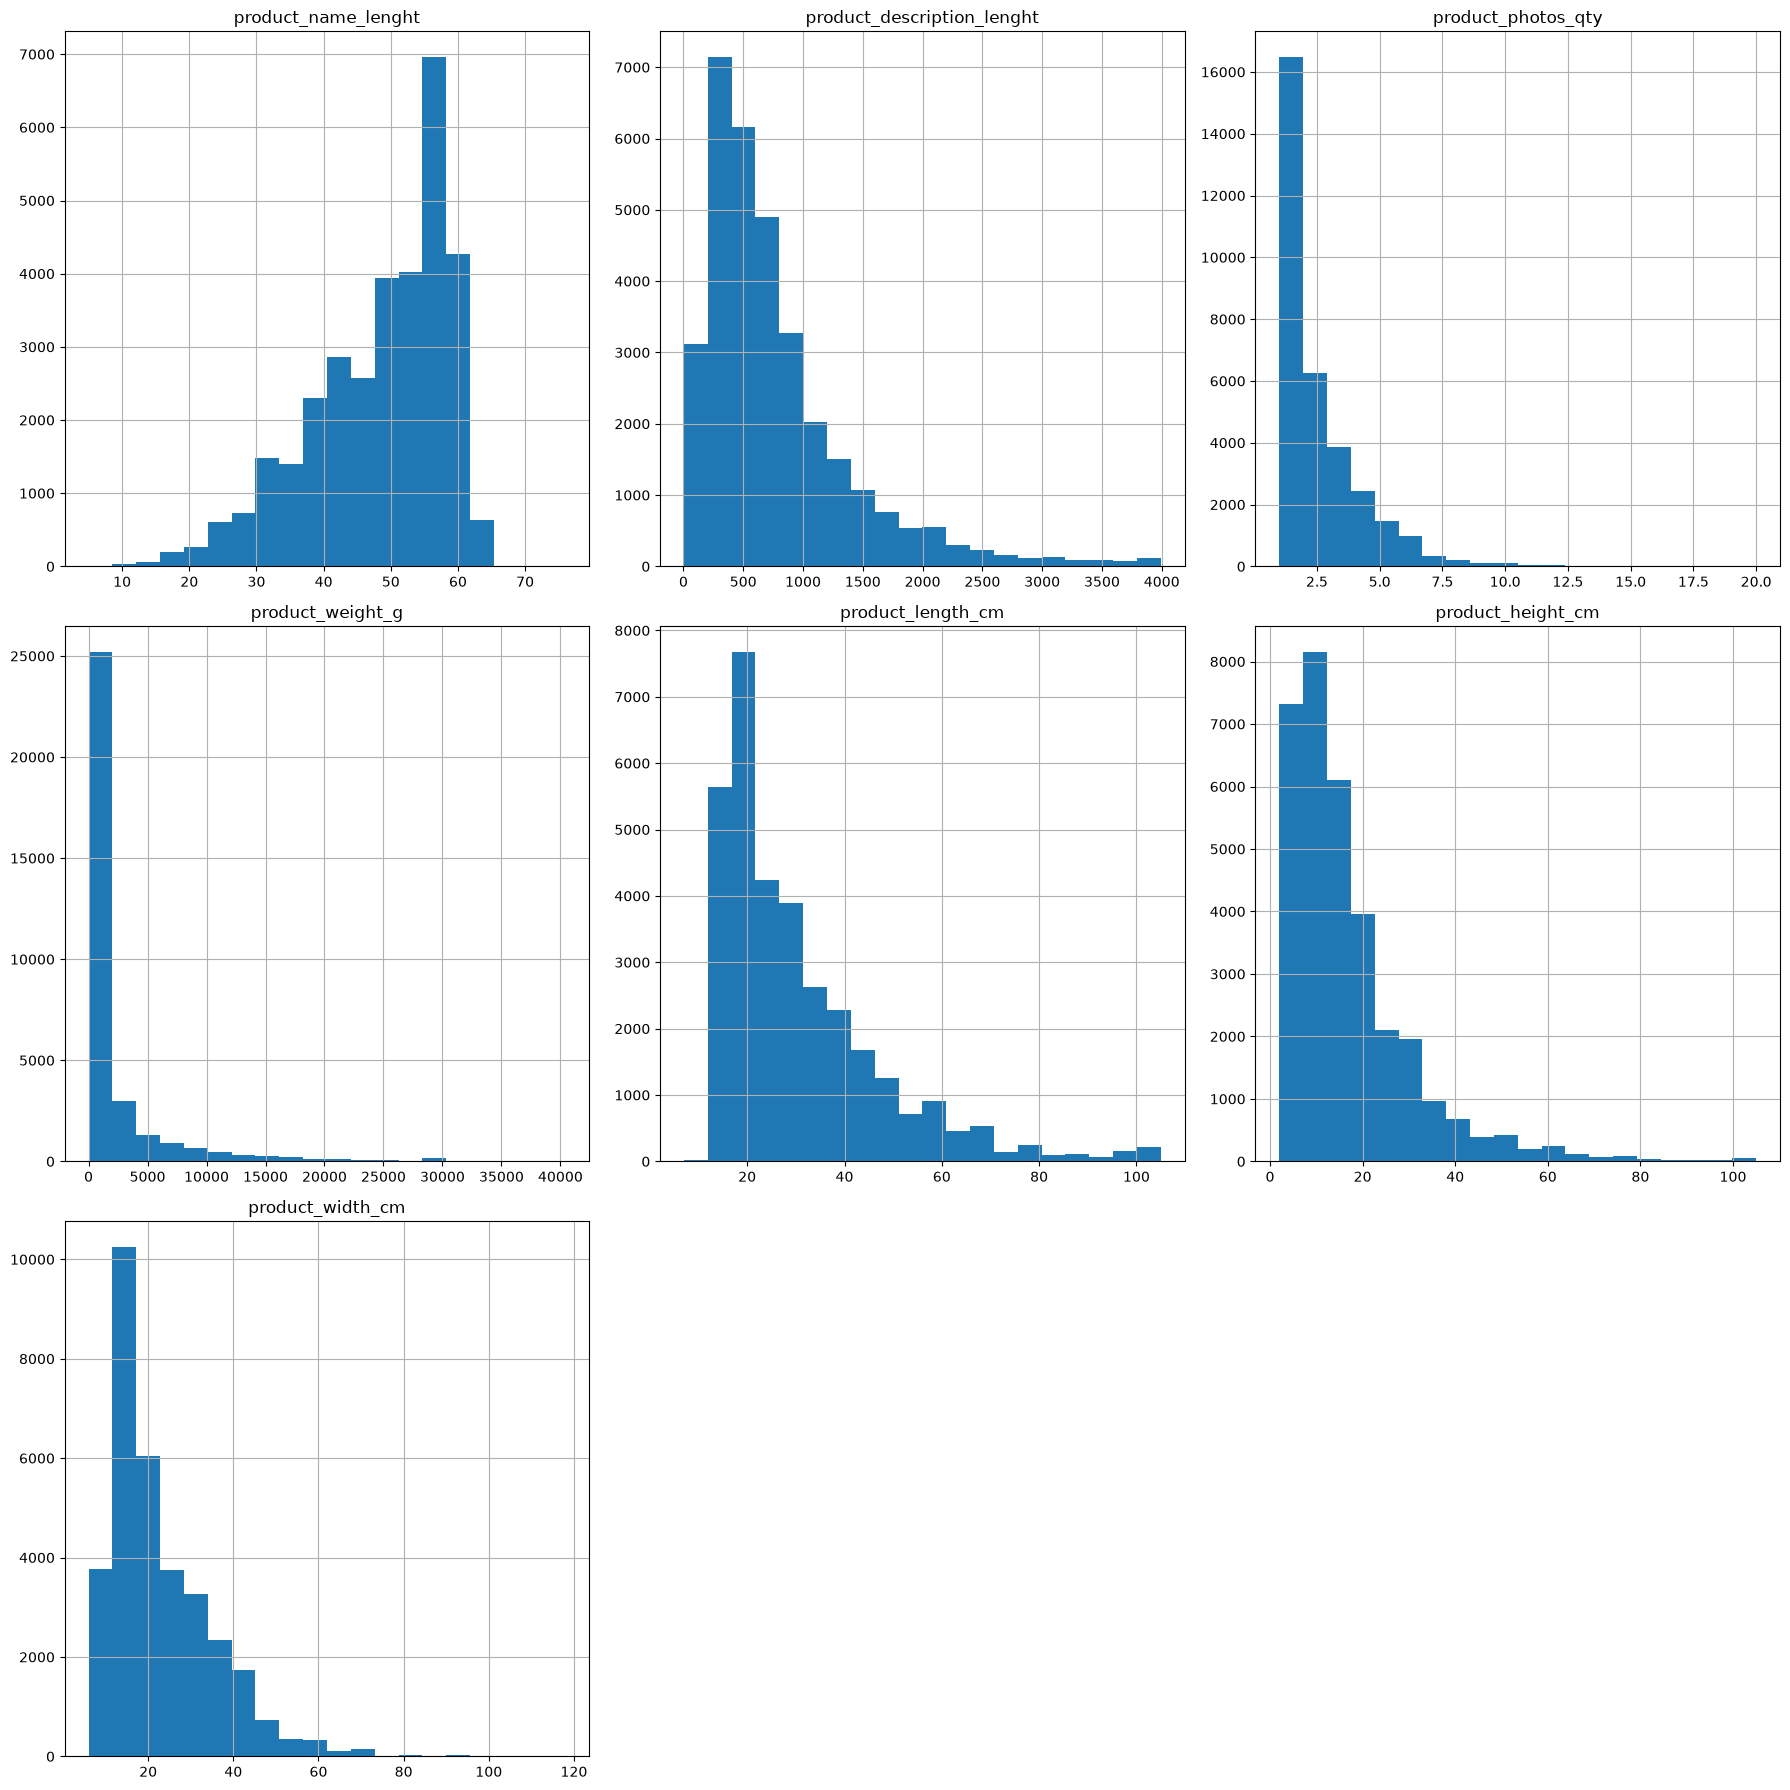

In [57]:
# Histogram of each numerical columns
products.hist(figsize=(18, 18), bins=20)
plt.tight_layout()
plt.show()

In [102]:
products.duplicated().sum()

np.int64(0)

In [107]:
products["product_category_name"].value_counts(dropna=False)

product_category_name
cama_mesa_banho                  3029
esporte_lazer                    2867
moveis_decoracao                 2657
beleza_saude                     2444
utilidades_domesticas            2335
                                 ... 
fashion_roupa_infanto_juvenil       5
casa_conforto_2                     5
pc_gamer                            3
seguros_e_servicos                  2
cds_dvds_musicais                   1
Name: count, Length: 74, dtype: int64

In [103]:
products["product_id"].duplicated().sum()

np.int64(0)

`Products` Dataset

- **Rows:** 32,951
- **Columns:** 9
- **Grain:** 1 row = 1 product.
- `product_id` identifies the product.
- `product_category_name` represents the product category.
- `product_name_lenght` and `product_description_lenght` represent the length of the product name and description.
- `product_photos_qty` represents the number of product photos.
- `product_weight_g` represents product weight in grams.
- `product_length_cm`, `product_height_cm`, and `product_width_cm` represent product dimensions.
- Missing values are present in product category and several product attribute columns.

### GEOLOCATION

In [64]:
geolocation.head()

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP


In [65]:
geolocation.shape

(1000163, 5)

In [66]:
geolocation.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000163 entries, 0 to 1000162
Data columns (total 5 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   geolocation_zip_code_prefix  1000163 non-null  int64  
 1   geolocation_lat              1000163 non-null  float64
 2   geolocation_lng              1000163 non-null  float64
 3   geolocation_city             1000163 non-null  str    
 4   geolocation_state            1000163 non-null  str    
dtypes: float64(2), int64(1), str(2)
memory usage: 38.2 MB


In [70]:
geolocation.isna().sum()

geolocation_zip_code_prefix    0
geolocation_lat                0
geolocation_lng                0
geolocation_city               0
geolocation_state              0
dtype: int64

In [69]:
geolocation.nunique()

geolocation_zip_code_prefix     19015
geolocation_lat                717363
geolocation_lng                717615
geolocation_city                 8011
geolocation_state                  27
dtype: int64

In [71]:
geolocation.duplicated().sum()

np.int64(261831)

In [72]:
geolocation["geolocation_zip_code_prefix"].duplicated().sum()

np.int64(981148)

`Geolocation` Dataset

- Rows: 1,000,163
- Columns: 5
- Missing values: None
- Grain: 1 row = 1 geolocation record associated with a ZIP code prefix.
- A ZIP code prefix can appear in multiple rows.
- 19,015 unique ZIP code prefixes are present.
- 261,831 rows are exact duplicates.
- The dataset contains latitude and longitude information, along with city and state.

### ORDERS

In [75]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [76]:
orders.shape

(99441, 8)

In [77]:
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 6.1 MB


In [78]:
orders.isna().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [79]:
orders.isna().mean() * 100

order_id                         0.000000
customer_id                      0.000000
order_status                     0.000000
order_purchase_timestamp         0.000000
order_approved_at                0.160899
order_delivered_carrier_date     1.793023
order_delivered_customer_date    2.981668
order_estimated_delivery_date    0.000000
dtype: float64

In [90]:
orders.nunique()

order_id                         99441
customer_id                      99441
order_status                         8
order_purchase_timestamp         98875
order_approved_at                90733
order_delivered_carrier_date     81018
order_delivered_customer_date    95664
order_estimated_delivery_date      459
dtype: int64

In [109]:
orders["order_status"].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [110]:
orders.duplicated().sum()

np.int64(0)

In [111]:
orders["order_id"].duplicated().sum()

np.int64(0)

`Orders` Dataset

- **Rows:** 99,441
- **Columns:** 8
- **Grain:** 1 row = 1 order.
- `order_id` uniquely identifies an order within the dataset.
- Each order is associated with a `customer_id`.
- `order_status` contains 8 distinct order statuses.
- Missing values occur mainly in order approval and delivery-related timestamps.
- Order timestamps are currently stored as strings and will require datetime conversion for temporal analysis.
- No exact duplicate rows were found.
- No duplicate `order_id` was found.

### ORDER ITEM

In [121]:
order_item.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [122]:
order_item.shape

(112650, 7)

In [123]:
order_item.info()

<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  str    
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  str    
 3   seller_id            112650 non-null  str    
 4   shipping_limit_date  112650 non-null  str    
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), str(4)
memory usage: 6.0 MB


In [125]:
order_item.isna().sum()

order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

In [124]:
order_item.nunique()

order_id               98666
order_item_id             21
product_id             32951
seller_id               3095
shipping_limit_date    93318
price                   5968
freight_value           6999
dtype: int64

In [127]:
order_item.duplicated().sum()

np.int64(0)

In [128]:
order_item["order_id"].duplicated().sum()

np.int64(13984)

In [131]:
order_item.groupby("order_id").size().describe()

count    98666.000000
mean         1.141731
std          0.538452
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max         21.000000
dtype: float64

`Order Items` Dataset

* **Rows:** 112,650
* **Columns:** 7
* **Grain:** 1 row = 1 item within an order.
* `order_id` identifies the associated order.
* `order_item_id` indicates the item sequence within an order.
* `product_id` identifies the product.
* `seller_id` identifies the seller associated with the item.
* `shipping_limit_date` represents the shipping limit date for the item.
* `price` represents the item price.
* `freight_value` represents the freight value.
* No missing values were found.
* An order can contain multiple items.
* No exact duplicate rows were found.


### PAYMENTS

In [86]:
payments.head(10)

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45
5,298fcdf1f73eb413e4d26d01b25bc1cd,1,credit_card,2,96.12
6,771ee386b001f06208a7419e4fc1bbd7,1,credit_card,1,81.16
7,3d7239c394a212faae122962df514ac7,1,credit_card,3,51.84
8,1f78449c87a54faf9e96e88ba1491fa9,1,credit_card,6,341.09
9,0573b5e23cbd798006520e1d5b4c6714,1,boleto,1,51.95


In [84]:
payments.shape

(103886, 5)

In [85]:
payments.info()

<class 'pandas.DataFrame'>
RangeIndex: 103886 entries, 0 to 103885
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   order_id              103886 non-null  str    
 1   payment_sequential    103886 non-null  int64  
 2   payment_type          103886 non-null  str    
 3   payment_installments  103886 non-null  int64  
 4   payment_value         103886 non-null  float64
dtypes: float64(1), int64(2), str(2)
memory usage: 4.0 MB


In [87]:
payments.isna().sum()

order_id                0
payment_sequential      0
payment_type            0
payment_installments    0
payment_value           0
dtype: int64

In [88]:
payments.nunique()

order_id                99440
payment_sequential         29
payment_type                5
payment_installments       24
payment_value           29077
dtype: int64

In [94]:
payments["payment_type"].value_counts()

payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64

In [97]:
payments.describe()

,payment_sequential,payment_installments,payment_value
count,103886.000000,103886.000000,103886.000000
mean,1.092679,2.853349,154.100380
std,0.706584,2.687051,217.494064
min,1.000000,0.000000,0.000000
25%,1.000000,1.000000,56.790000
50%,1.000000,1.000000,100.000000
75%,1.000000,4.000000,171.837500
max,29.000000,24.000000,13664.080000


In [132]:
payments.duplicated().sum()

np.int64(0)

In [133]:
payments["order_id"].duplicated().sum()

np.int64(4446)

In [134]:
payments.groupby("order_id").size().describe()

count    99440.000000
mean         1.044710
std          0.381166
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max         29.000000
dtype: float64

`Payments` Dataset

* **Rows:** 103,886
* **Columns:** 5
* **Grain:** 1 row = 1 payment record.
* `order_id` identifies the associated order.
* `payment_sequential` indicates the payment sequence within an order.
* `payment_type` represents the payment method.
* `payment_installments` represents the number of installments.
* `payment_value` represents the payment value.
* No missing values were found.
* An order can have multiple payment records.
* No exact duplicate rows were found.


### REVIEWS

In [113]:
reviews.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [114]:
reviews.shape

(99224, 7)

In [115]:
reviews.info()

<class 'pandas.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   review_id                99224 non-null  str  
 1   order_id                 99224 non-null  str  
 2   review_score             99224 non-null  int64
 3   review_comment_title     11568 non-null  str  
 4   review_comment_message   40977 non-null  str  
 5   review_creation_date     99224 non-null  str  
 6   review_answer_timestamp  99224 non-null  str  
dtypes: int64(1), str(6)
memory usage: 5.3 MB


In [116]:
reviews.isna().sum()

review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64

In [117]:
reviews.isna().mean() * 100

review_id                   0.000000
order_id                    0.000000
review_score                0.000000
review_comment_title       88.341530
review_comment_message     58.702532
review_creation_date        0.000000
review_answer_timestamp     0.000000
dtype: float64

In [118]:
reviews.nunique()

review_id                  98410
order_id                   98673
review_score                   5
review_comment_title        4527
review_comment_message     36159
review_creation_date         636
review_answer_timestamp    98248
dtype: int64

In [135]:
reviews.duplicated().sum()

np.int64(0)

In [136]:
reviews["review_score"].value_counts().sort_index()

review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64

In [137]:
reviews["order_id"].duplicated().sum()

np.int64(551)

In [140]:
reviews["review_id"].duplicated().sum()

np.int64(814)

`Reviews` Dataset

- **Rows:** 99,224
- **Columns:** 7
- The dataset contains customer review information associated with orders.
- `review_id` identifies a review record.
- `order_id` identifies the associated order.
- `review_score` represents the review score, ranging from 1 to 5.
- `review_comment_title` and `review_comment_message` contain optional review text.
- `review_creation_date` and `review_answer_timestamp` contain review-related timestamps.
- Missing values are present mainly in the review comment fields.
- No exact duplicate rows were found.
- `order_id` and `review_id` are not unique within the dataset.

### TRANSLATED PRODUCTS

In [22]:
translated_products.head()

,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


In [23]:
translated_products.shape

(71, 2)

In [99]:
translated_products.info()

<class 'pandas.DataFrame'>
RangeIndex: 71 entries, 0 to 70
Data columns (total 2 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   product_category_name          71 non-null     str  
 1   product_category_name_english  71 non-null     str  
dtypes: str(2)
memory usage: 1.2 KB


In [138]:
translated_products.nunique()

product_category_name            71
product_category_name_english    71
dtype: int64

In [139]:
translated_products.duplicated().sum()

np.int64(0)

`Translated Products` Dataset

- **Rows:** 71
- **Columns:** 2
- **Grain:** 1 row = 1 product category translation.
- `product_category_name` contains the original product category name.
- `product_category_name_english` contains the English translation.
- No missing values were found.
- The dataset serves as a mapping between the original and English product category names.